In [1]:
# Import libraries
import pandas as pd
import pyarrow.parquet as pq
import geopandas as gpd
import numpy as np
from shapely.geometry import box
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Inspect the parquet schema and total row count without loading data into memory
pf = pq.ParquetFile("../data/raw/dietrich/buildings_preds.parquet")
print(pf.schema)
print(f"Total rows: {pf.metadata.num_rows}")

required group field_id=-1 duckdb_schema {
  optional double field_id=-1 2021-02-24;
  optional double field_id=-1 2021-05-24;
  optional double field_id=-1 2021-08-24;
  optional double field_id=-1 2021-11-24;
  optional double field_id=-1 2022-02-24;
  optional double field_id=-1 2022-05-24;
  optional double field_id=-1 2022-08-24;
  optional double field_id=-1 2022-11-24;
  optional double field_id=-1 2023-02-24;
  optional double field_id=-1 2023-05-24;
  optional double field_id=-1 2023-08-24;
  optional double field_id=-1 2023-11-24;
  optional binary field_id=-1 ADM1_EN (String);
  optional binary field_id=-1 ADM2_EN (String);
  optional binary field_id=-1 ADM3_EN (String);
  optional binary field_id=-1 ADM4_EN (String);
  optional binary field_id=-1 adm1_id (String);
  optional binary field_id=-1 adm2_id (String);
  optional binary field_id=-1 adm3_id (String);
  optional binary field_id=-1 adm4_id (String);
  optional double field_id=-1 area;
  optional int64 field_id=-1 buil

In [3]:
# Load 12 quarterly SAR backscatter columns plus building metadata from the parquet file
damage_cols = [
    "2021-02-24", "2021-05-24", "2021-08-24", "2021-11-24",
    "2022-02-24", "2022-05-24", "2022-08-24", "2022-11-24",
    "2023-02-24", "2023-05-24", "2023-08-24", "2023-11-24"
]

df = pq.read_table(
    "../data/raw/dietrich/buildings_preds.parquet",
    columns=["building_id", "lon", "lat", "ADM1_EN", "ADM2_EN", "ADM3_EN",
             "unosat_damage", "unosat_aoi"] + damage_cols
).to_pandas()

print(df.shape)

(26564415, 20)


In [4]:
# Preview the first few rows
df.head()

,building_id,lon,lat,ADM1_EN,ADM2_EN,ADM3_EN,unosat_damage,unosat_aoi,2021-02-24,2021-05-24,2021-08-24,2021-11-24,2022-02-24,2022-05-24,2022-08-24,2022-11-24,2023-02-24,2023-05-24,2023-08-24,2023-11-24
0,3212,33.812886,44.746826,Autonomous Republic of Crimea,Bakhchysaraiskyi,Aromatnenska,NaN,NaN,62.000000,96.000000,51.000000,82.000000,49.000000,118.000000,67.000000,51.000000,79.000000,164.000000,82.000000,77.000000
1,3220,33.810598,44.748922,Autonomous Republic of Crimea,Bakhchysaraiskyi,Aromatnenska,NaN,NaN,56.227438,92.987944,76.452556,75.339825,49.679835,144.076334,95.101623,51.243512,50.444280,163.453823,91.304330,89.703831
2,3221,33.810575,44.748971,Autonomous Republic of Crimea,Bakhchysaraiskyi,Aromatnenska,NaN,NaN,53.574044,85.477407,80.773363,93.002046,49.357180,132.412481,84.573380,59.216686,46.371253,185.687179,86.895395,89.801346
3,3222,33.810495,44.750143,Autonomous Republic of Crimea,Bakhchysaraiskyi,Aromatnenska,NaN,NaN,71.773841,84.117623,90.244423,111.588447,69.175882,93.554245,65.666462,58.626540,62.762292,133.653685,81.825834,112.797778
4,3223,33.810859,44.753860,Autonomous Republic of Crimea,Bakhchysaraiskyi,Aromatnenska,NaN,NaN,66.220393,95.684464,74.190286,97.958250,58.178643,68.095143,54.410679,59.684464,59.368929,79.494179,58.220393,59.696107


In [5]:
# Compute absolute backscatter change between Aug 2022 and the 2021 pre-war quarterly mean
pre_war_cols = ["2021-02-24", "2021-05-24", "2021-08-24", "2021-11-24"]

df["baseline_backscatter"] = df[pre_war_cols].mean(axis=1)
df["damage_proxy_aug22"] = (df["2022-08-24"] - df["baseline_backscatter"]).abs()

print(df["damage_proxy_aug22"].describe())

count    2.656442e+07
mean     1.469037e+01
std      1.424963e+01
min      0.000000e+00
25%      4.899018e+00
50%      1.072901e+01
75%      1.987324e+01
max      2.174389e+02
Name: damage_proxy_aug22, dtype: float64


In [6]:
# Convert building coordinates to a GeoDataFrame in WGS84 and reproject to UTM zone 37N
geometry = gpd.points_from_xy(df["lon"], df["lat"])
gdf_buildings = gpd.GeoDataFrame(df, geometry=geometry, crs="EPSG:4326")
gdf_buildings = gdf_buildings.to_crs("EPSG:32637")

print(gdf_buildings.crs)
print(gdf_buildings.total_bounds)

EPSG:32637
[-744942.90238088 4927719.6544805   588832.61247872 5849318.86680796]


In [7]:
# Load UNOSAT AOI boundaries and isolate the Mariupol AOI (UKR1) in UTM
aois = gpd.read_file("../data/raw/unosat/unosat_aois.geojson")
mariupol_aoi = aois[aois["aoi"] == "UKR1"].to_crs("EPSG:32637")

print(f"Mariupol AOI bounds: {mariupol_aoi.total_bounds}")

Mariupol AOI bounds: [ 385659.40026261 5215427.91831737  401049.26139961 5222278.01046936]


In [8]:
# Build a 10m grid covering the Mariupol AOI bounding box
xmin, ymin, xmax, ymax = mariupol_aoi.total_bounds
cell_size = 10

xs = np.arange(xmin, xmax, cell_size)
ys = np.arange(ymin, ymax, cell_size)

cells_m = [box(x, y, x + cell_size, y + cell_size) for x in xs for y in ys]
grid_mariupol = gpd.GeoDataFrame({"cell_id": range(len(cells_m)), "geometry": cells_m}, crs="EPSG:32637")

print(f"Mariupol grid cells: {len(grid_mariupol):,}")

Mariupol grid cells: 1,055,754


In [9]:
# Clip buildings to Mariupol, join to 10m grid, and compute mean absolute backscatter change per cell
buildings_mariupol = gpd.clip(gdf_buildings, mariupol_aoi)
print(f"Buildings in Mariupol: {len(buildings_mariupol):,}")

joined_m = gpd.sjoin(buildings_mariupol, grid_mariupol, how="left", predicate="within")

joined_m["baseline"] = joined_m[pre_war_cols].mean(axis=1)
joined_m["damage_proxy_aug22"] = (joined_m["2022-08-24"] - joined_m["baseline"]).abs()

cell_stats_m = joined_m.groupby("cell_id").agg(
    n_buildings=("building_id", "count"),
    damage_proxy_aug22=("damage_proxy_aug22", "mean"),
).reset_index()

grid_mariupol_damage = grid_mariupol.merge(cell_stats_m, on="cell_id", how="left")
cells_with_data = grid_mariupol_damage[grid_mariupol_damage["n_buildings"].notna()]

print(cells_with_data["damage_proxy_aug22"].describe())

Buildings in Mariupol: 29,325
count    28774.000000
mean        34.117620
std         33.163880
min          0.000000
25%          9.815581
50%         22.914287
75%         47.779642
max        217.438943
Name: damage_proxy_aug22, dtype: float64


In [10]:
# Flag how many buildings in the Mariupol join have a UNOSAT class 1 or 2 label
labels = gpd.read_file("../data/raw/unosat/unosat_labels.geojson")

labeled_building_ids = set(
    df[(df["unosat_aoi"] == "UKR1") & (df["unosat_damage"].isin([1.0, 2.0]))]["building_id"]
)

print(f"Buildings with UNOSAT class 1 or 2 label: {len(labeled_building_ids):,}")

Buildings with UNOSAT class 1 or 2 label: 2,553


In [11]:
# Tag each grid cell as labeled (contains at least one UNOSAT class 1/2 building) or unlabeled, and print median stats
joined_m["has_unosat_label"] = joined_m["building_id"].isin(labeled_building_ids)

cell_label = joined_m.groupby("cell_id")["has_unosat_label"].any().reset_index()
cell_label.columns = ["cell_id", "has_label"]

grid_mariupol_damage = grid_mariupol_damage.merge(cell_label, on="cell_id", how="left")

labeled_cells = grid_mariupol_damage[grid_mariupol_damage["has_label"] == True]["damage_proxy_aug22"].dropna()
unlabeled_cells = grid_mariupol_damage[grid_mariupol_damage["has_label"] == False]["damage_proxy_aug22"].dropna()

print(f"Labeled cells: {len(labeled_cells):,}  |  median abs change: {labeled_cells.median():.2f}")
print(f"Unlabeled cells: {len(unlabeled_cells):,}  |  median abs change: {unlabeled_cells.median():.2f}")

Labeled cells: 2,548  |  median abs change: 58.71
Unlabeled cells: 26,226  |  median abs change: 21.24


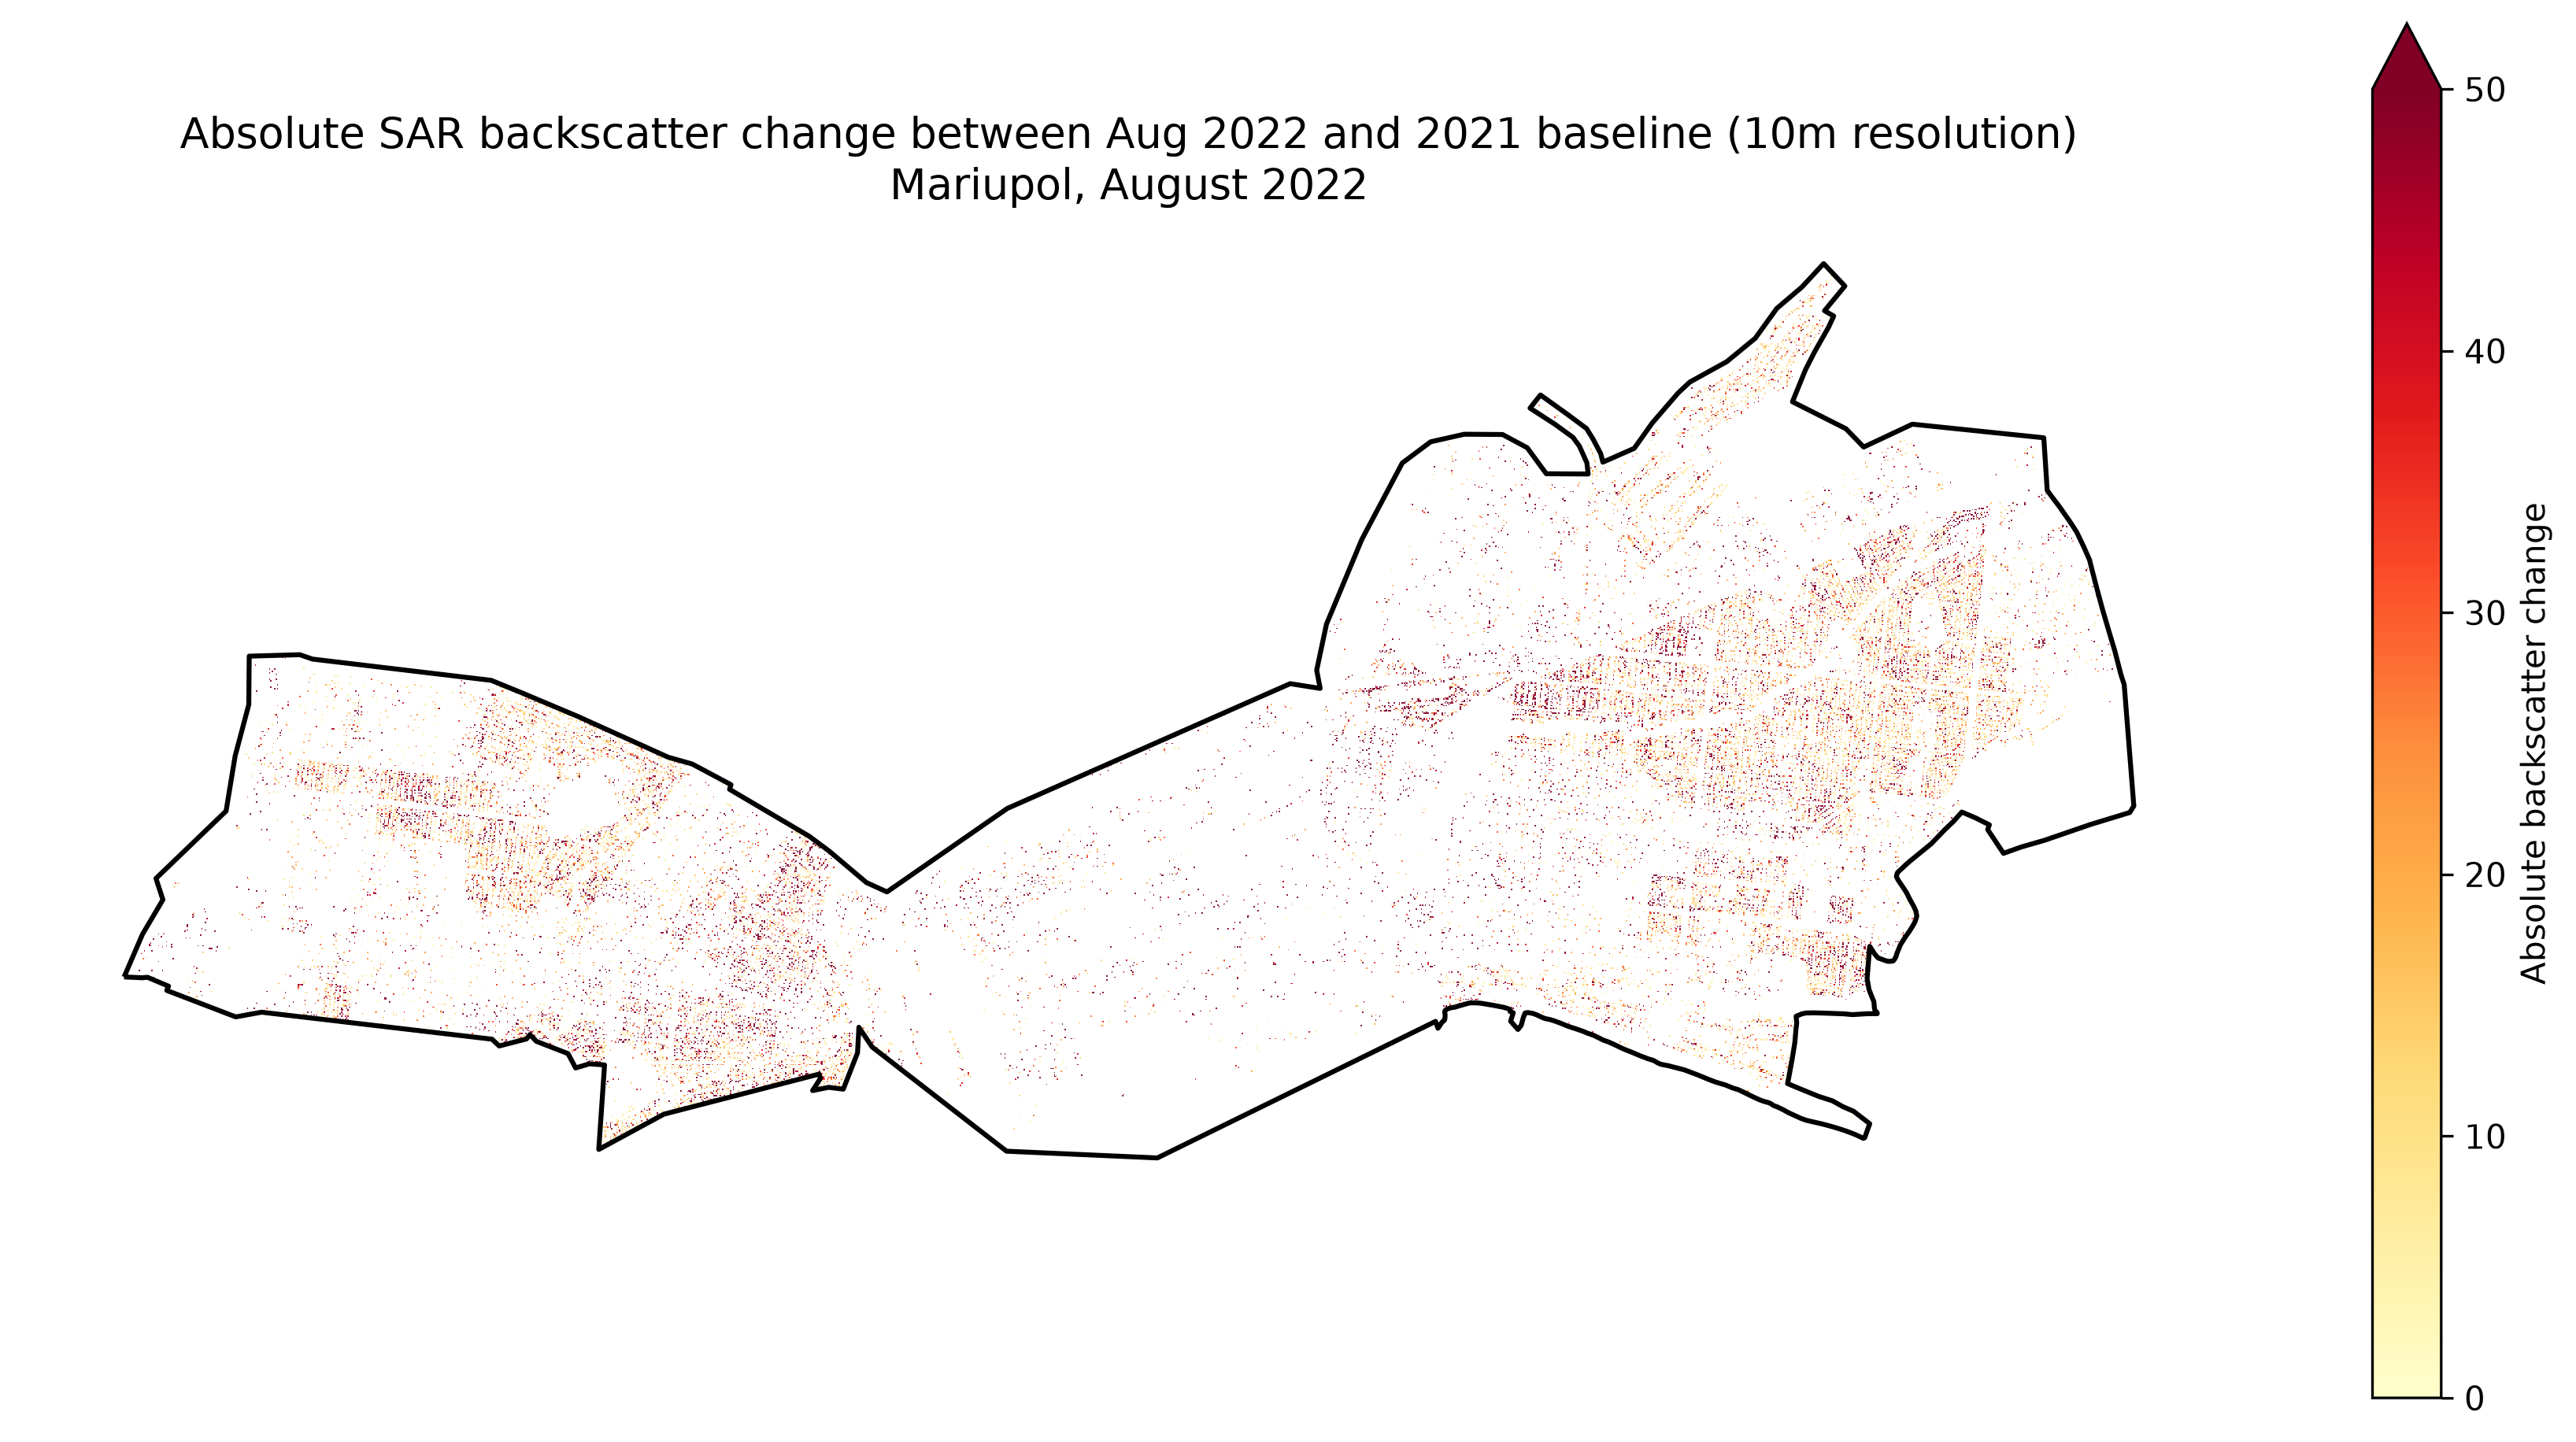

In [12]:
# Plot a 10m resolution choropleth of absolute SAR backscatter change for Mariupol
fig, ax = plt.subplots(figsize=(12, 10), dpi=300)

cells_with_data.plot(
    column="damage_proxy_aug22",
    ax=ax,
    cmap="YlOrRd",
    vmin=0, vmax=50,
    legend=True,
    legend_kwds={"label": "Absolute backscatter change", "shrink": 0.6},
    alpha=0.9
)

mariupol_aoi.boundary.plot(ax=ax, color="black", linewidth=1.5)

ax.set_title("Absolute SAR backscatter change between Aug 2022 and 2021 baseline (10m resolution)\nMariupol, August 2022", fontsize=13)
ax.set_axis_off()
plt.tight_layout()
plt.savefig("../outputs/figures/mariupol_10m_abs_damage.png", dpi=300, bbox_inches="tight")
plt.show()

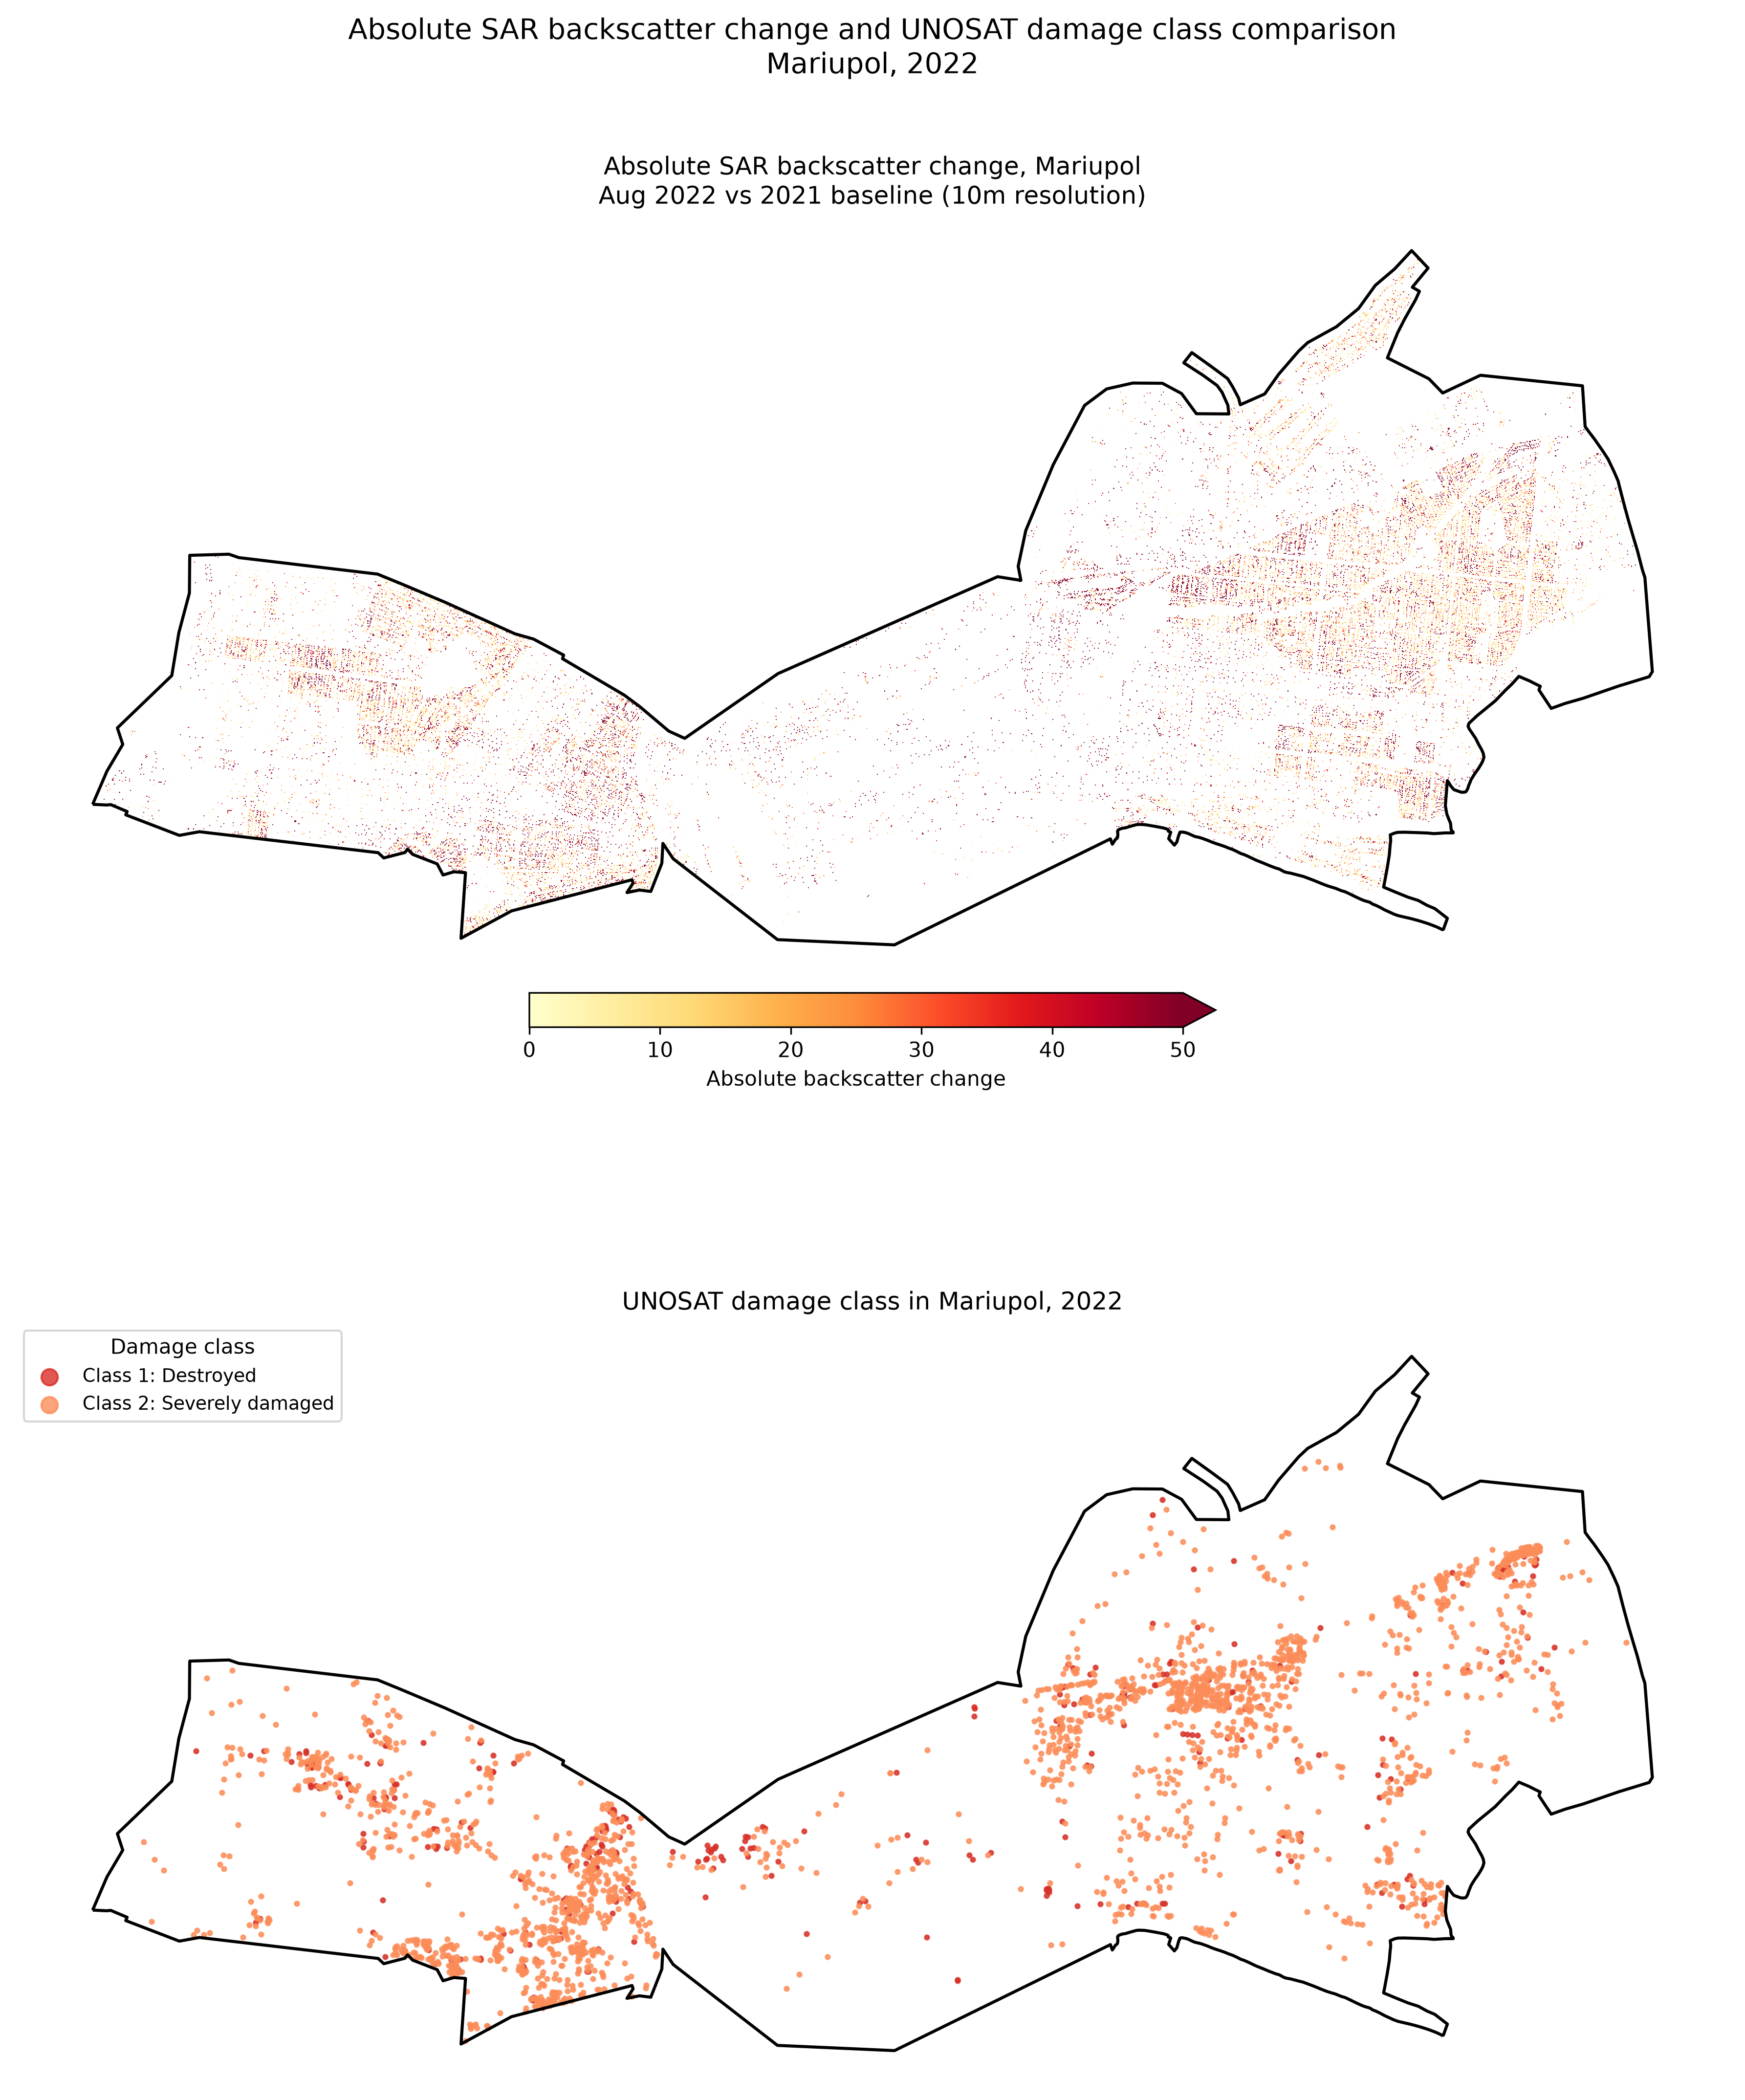

In [13]:
# Stacked figure: SAR damage choropleth on top, UNOSAT class 1 and 2 points below
mariupol_aoi_4326 = mariupol_aoi.to_crs("EPSG:4326")
labels_mariupol = labels[labels.geometry.within(mariupol_aoi_4326.union_all())]
labels_c1 = labels_mariupol[labels_mariupol["damage"] == 1].to_crs("EPSG:32637")
labels_c2 = labels_mariupol[labels_mariupol["damage"] == 2].to_crs("EPSG:32637")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 18), dpi=300)

cells_with_data.plot(
    column="damage_proxy_aug22",
    ax=ax1,
    cmap="YlOrRd",
    vmin=0, vmax=50,
    legend=True,
    legend_kwds={
        "label": "Absolute backscatter change",
        "shrink": 0.4,
        "orientation": "horizontal",
        "pad": 0.01,
    },
    alpha=0.9
)
mariupol_aoi.boundary.plot(ax=ax1, color="black", linewidth=1.5)
ax1.set_title("Absolute SAR backscatter change, Mariupol\nAug 2022 vs 2021 baseline (10m resolution)", fontsize=12)
ax1.set_axis_off()

labels_c1.plot(ax=ax2, color="#d73027", markersize=4, alpha=0.8, label="Class 1: Destroyed")
labels_c2.plot(ax=ax2, color="#fc8d59", markersize=4, alpha=0.8, label="Class 2: Severely damaged")
mariupol_aoi.boundary.plot(ax=ax2, color="black", linewidth=1.5)
ax2.legend(title="Damage class", loc="upper left", fontsize=9, markerscale=4)
ax2.set_title("UNOSAT damage class in Mariupol, 2022", fontsize=12)
ax2.set_axis_off()

fig.suptitle("Absolute SAR backscatter change and UNOSAT damage class comparison\nMariupol, 2022", fontsize=14, y=0.90)
plt.tight_layout()
plt.savefig("../outputs/figures/mariupol_stacked_abs.png", dpi=300, bbox_inches="tight")
plt.show()

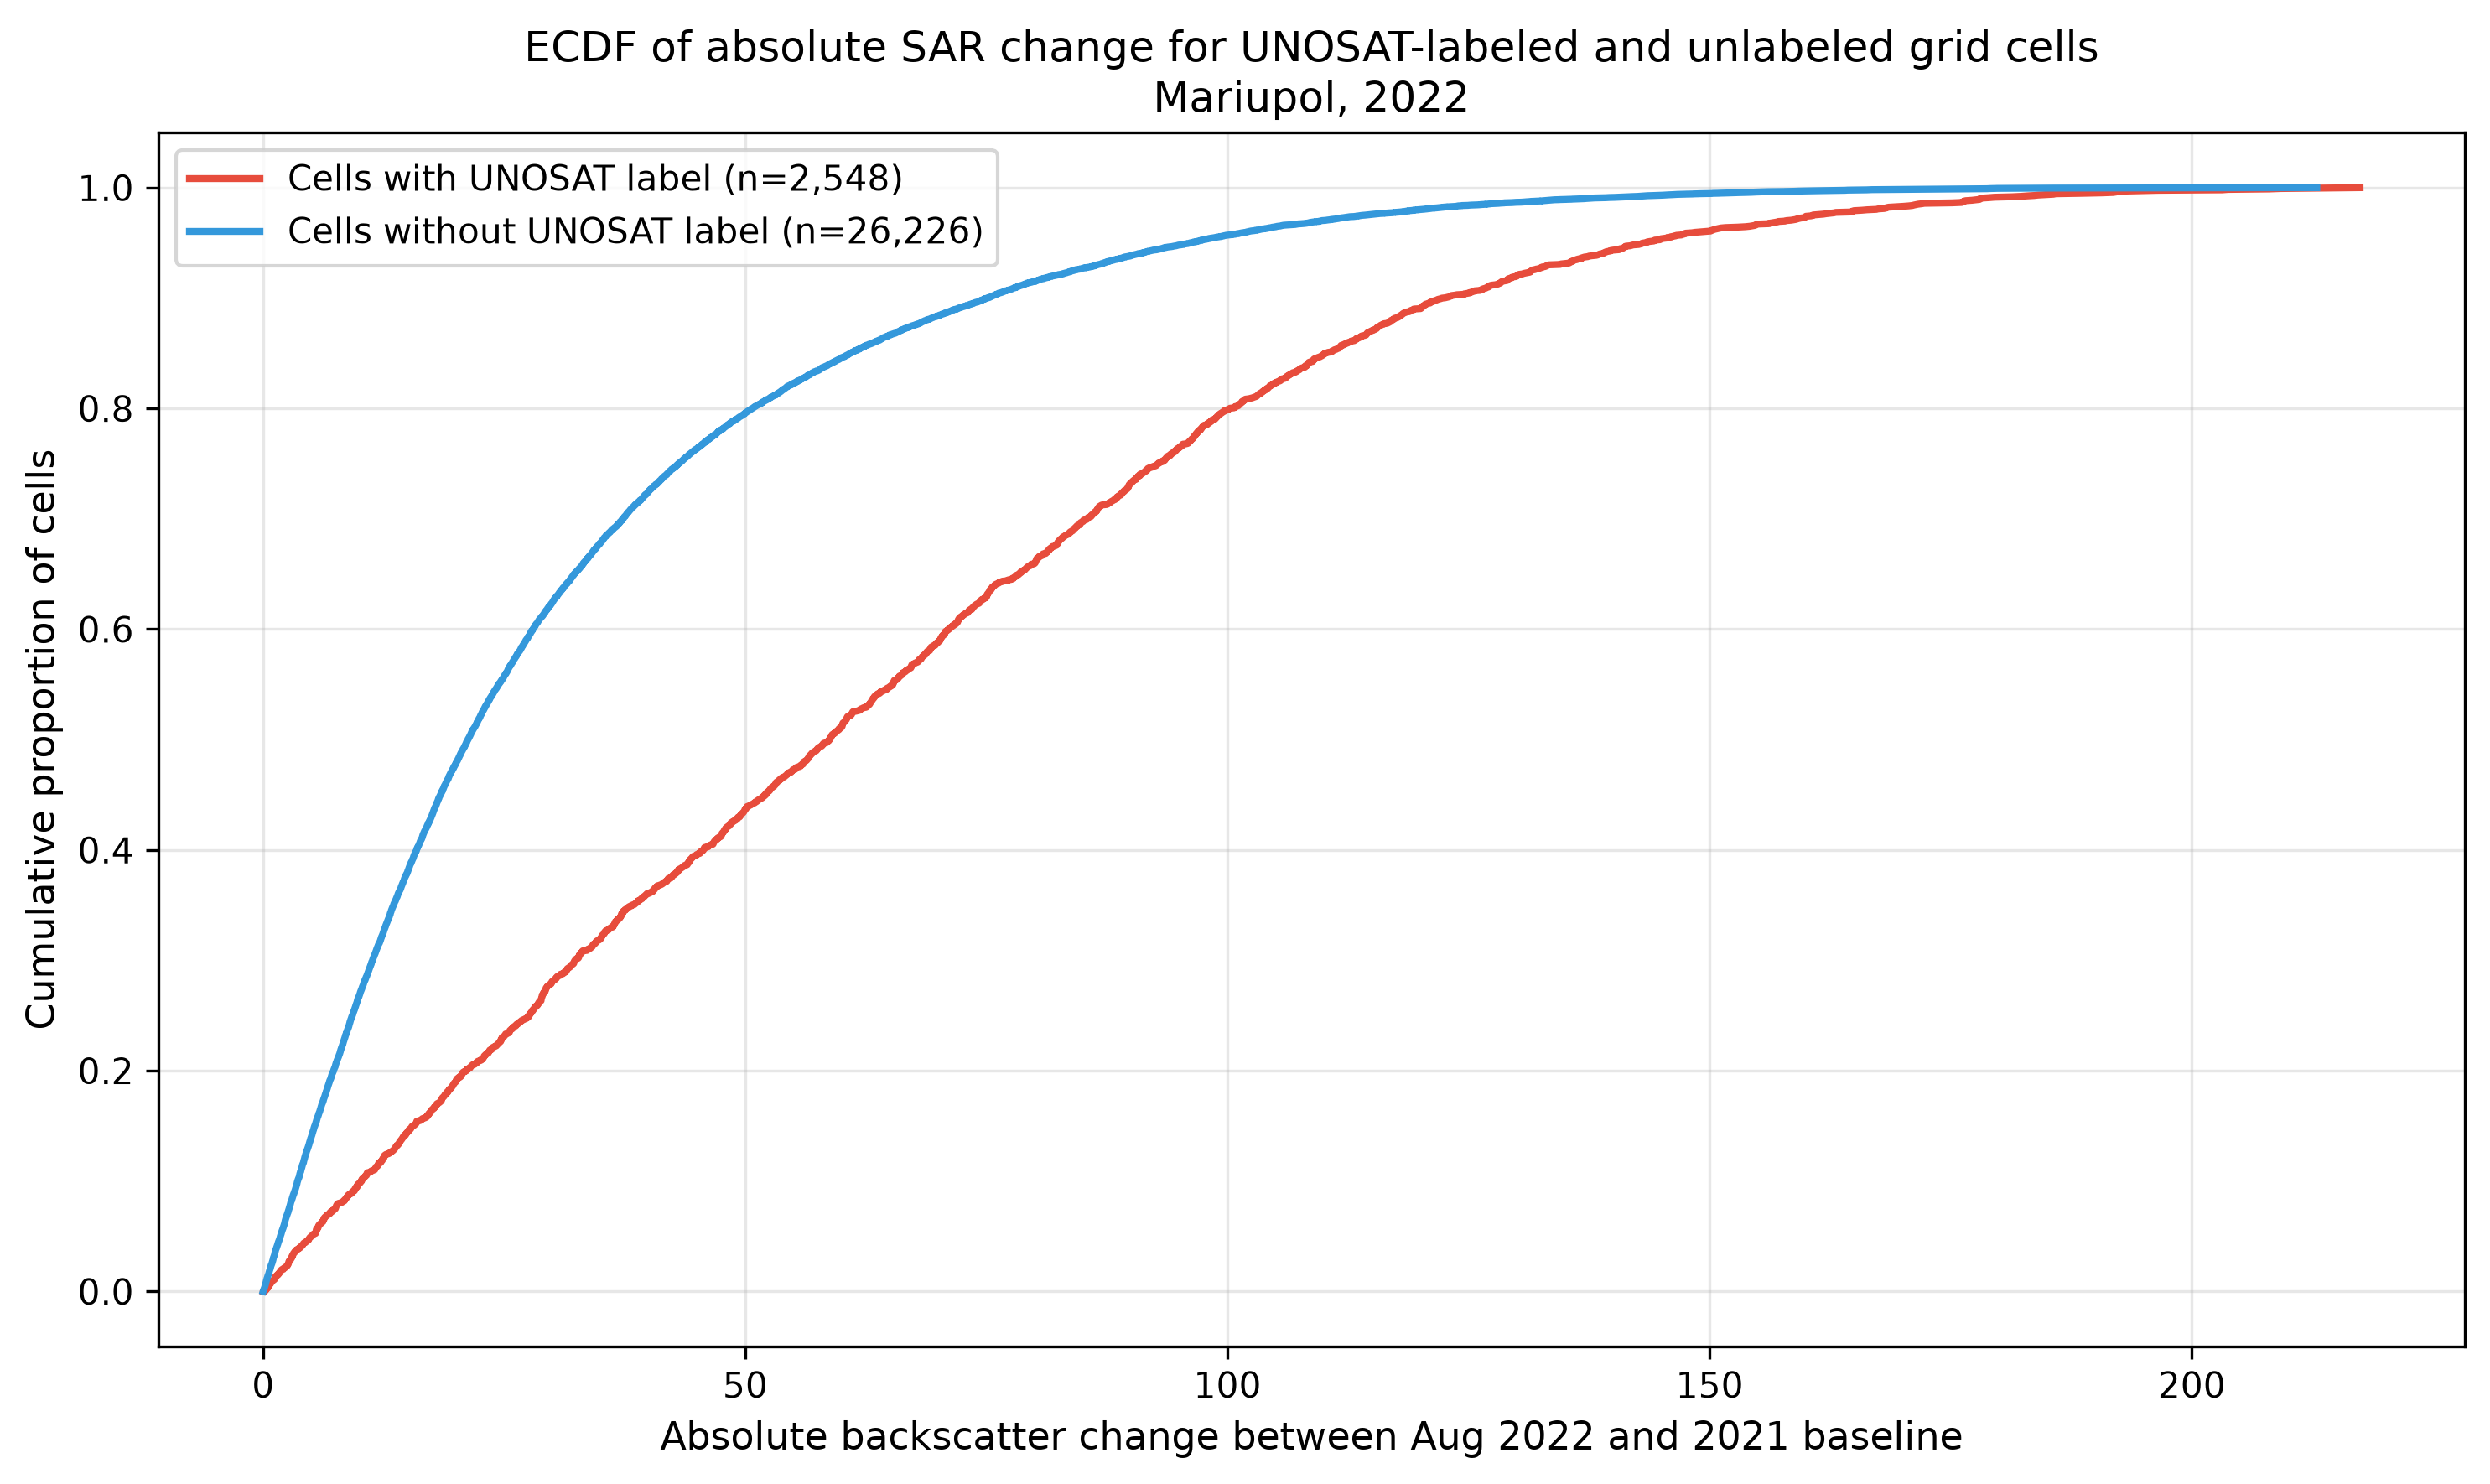

In [14]:
# ECDF comparing absolute SAR change between grid cells with and without UNOSAT damage labels
labeled_sorted = labeled_cells.sort_values()
unlabeled_sorted = unlabeled_cells.sort_values()

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

ax.plot(labeled_sorted,   np.linspace(0, 1, len(labeled_sorted)),
        color="#e74c3c", linewidth=2, label=f"Cells with UNOSAT label (n={len(labeled_sorted):,})")
ax.plot(unlabeled_sorted, np.linspace(0, 1, len(unlabeled_sorted)),
        color="#3498db", linewidth=2, label=f"Cells without UNOSAT label (n={len(unlabeled_sorted):,})")

ax.set_xlabel("Absolute backscatter change between Aug 2022 and 2021 baseline", fontsize=11)
ax.set_ylabel("Cumulative proportion of cells", fontsize=11)
ax.set_title("ECDF of absolute SAR change for UNOSAT-labeled and unlabeled grid cells\nMariupol, 2022", fontsize=12)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../outputs/figures/mariupol_ecdf_abs_labeled_vs_not.png", dpi=300, bbox_inches="tight")
plt.show()

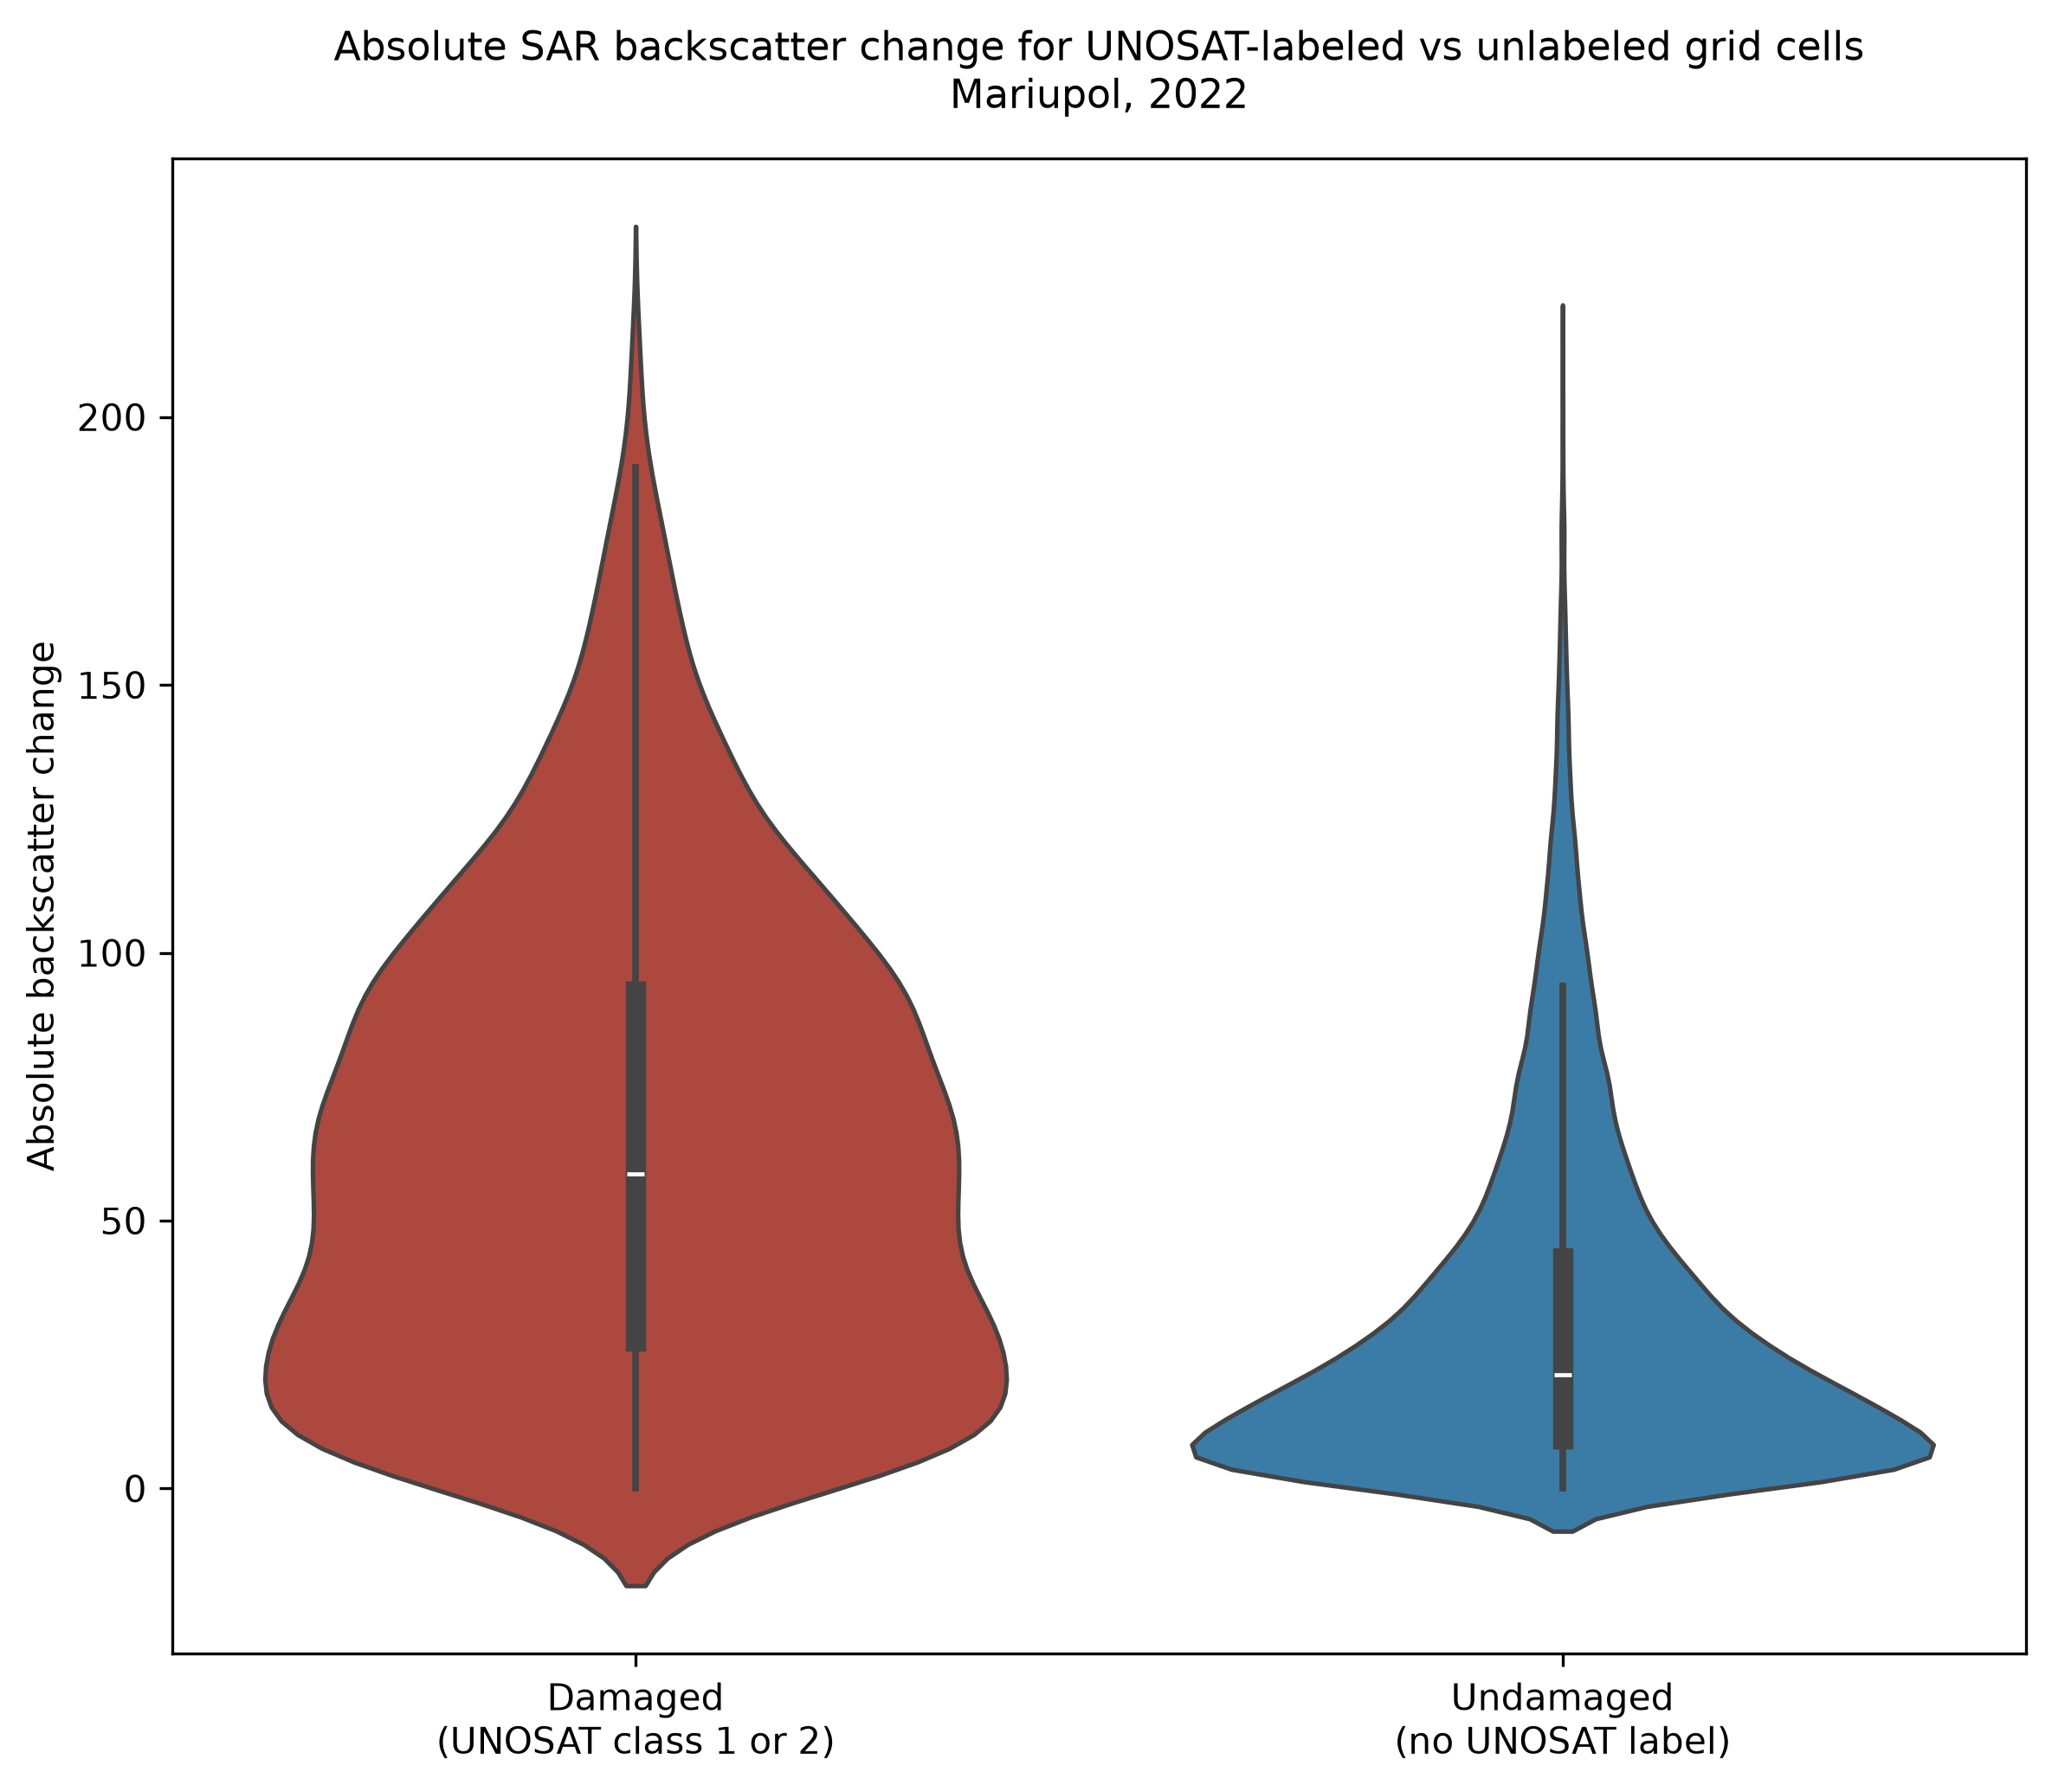

In [15]:
# Violin plot comparing absolute SAR change distribution for labeled vs unlabeled grid cells
plot_df = pd.DataFrame({
    "group": (["Damaged\n(UNOSAT class 1 or 2)"] * len(labeled_cells) +
              ["Undamaged\n(no UNOSAT label)"] * len(unlabeled_cells)),
    "abs_change": np.concatenate([labeled_cells.values, unlabeled_cells.values])
})

fig, ax = plt.subplots(figsize=(8, 7), dpi=300)

sns.violinplot(
    x="group", y="abs_change", data=plot_df,
    hue="group",
    palette={"Damaged\n(UNOSAT class 1 or 2)": "#c0392b",
             "Undamaged\n(no UNOSAT label)": "#2980b9"},
    legend=False,
    ax=ax
)

ax.set_xlabel("")
ax.set_ylabel("Absolute backscatter change", fontsize=10)
ax.set_title(
    "Absolute SAR backscatter change for UNOSAT-labeled vs unlabeled grid cells\nMariupol, 2022",
    fontsize=11, pad=14
)

plt.tight_layout()
plt.savefig("../outputs/figures/mariupol_violin_abs.png", dpi=300, bbox_inches="tight")
plt.show()